# NEXUS-OPS: Quantum-Classical Hybrid Biomedical Signal Classifier
## Qiskit Fall Fest 2026 — Track: Project Q (PS-Q1)

**Repository:** `NEXUS-OPS-PS-Q1`  
**Target Hardware:** Processor A (5-Qubit Baseline) vs. Processor B (9-Qubit Heavy-Hex Sparse Primary)  
**Future Proposed Architecture:** Processor D (12-Qubit Ring-Star Dual-Frequency Topology)  
**Authors:** NEXUS-OPS Technical Team  

---

### Executive Summary & Scope Boundary
This notebook presents the complete, reproducible Phase 1 demonstration of the **NEXUS-OPS Biomedical Signal Classifier** for ventricular ectopic beat (VEB) detection using continuous-lead electrocardiogram (ECG) records from the MIT-BIH Arrhythmia Database.

> **Formal Organizer Scope Notice (QFF Technical Program Cell):**
> - **Phase 1 Scope:** Evaluates **Processor A** (5-qubit baseline capacity rejection) and **Processor B** (9-qubit sparse execution) only.
> - **Phase 2 Scope:** Processor C and Processor D implementations belong strictly to Phase 2. The proposed Processor D architectural design is presented in Section 14 as a conceptual engineering blueprint for human evaluator assessment.
> - **Hardware Execution Notice:** All quantum simulations in this notebook are executed on local statevector and synthetic noise models (`qiskit-aer`). **No physical IBM Quantum QPU execution has been performed or submitted.**
> - **Feature Latency Disclosure:** The `post_rr` feature requires detection of the subsequent R-peak and therefore incorporates retrospective lookahead. It is an offline clinical benchmark feature, not an instantaneous real-time indicator.

In [1]:
# Cell 1: Environment and Dependency Verification
import sys
import os
import json
import time
from pathlib import Path

# Ensure project root is on sys.path
PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qiskit
import qiskit_aer
import sklearn

print("=" * 65)
print("NEXUS-OPS EXECUTION ENVIRONMENT VERIFICATION")
print("=" * 65)
print(f"Python Version    : {sys.version.split()[0]} ({sys.platform})")
print(f"Qiskit Version    : {qiskit.__version__}")
print(f"Qiskit Aer Version: {qiskit_aer.__version__}")
print(f"NumPy Version     : {np.__version__}")
print(f"SciKit-Learn      : {sklearn.__version__}")
print(f"Pandas Version    : {pd.__version__}")
print(f"Working Directory : {PROJECT_ROOT}")
print("=" * 65)
print("Environment status: ALL DEPENDENCIES OPERATIONAL")

NEXUS-OPS EXECUTION ENVIRONMENT VERIFICATION
Python Version    : 3.13.7 (win32)
Qiskit Version    : 2.5.2
Qiskit Aer Version: 0.17.2
NumPy Version     : 2.5.4
SciKit-Learn      : 1.9.1
Pandas Version    : 3.0.6
Working Directory : C:\Data\Projects\NEXUS-OPS\NEXUS-OPS\PS-Q1-Biomedical-Classifier
Environment status: ALL DEPENDENCIES OPERATIONAL


---
## 2. Dataset Provenance, Cohort Splitting, & Protocol B Governance

### Patient-Level Isolation Protocol
To guarantee zero data leakage and realistic generalization, we enforce **strict patient-level segregation** across the MIT-BIH Arrhythmia Database:
- **Training / Development Cohort (Records 106 & 119):** Used exclusively for signal segmentation, feature distribution estimation, and Leave-One-Record-Out (LORO) cross-validation.
- **Independent Held-Out Test Cohort (Records 200 & 208):** Strictly quarantined. Never exposed during scaler fitting, hyperparameter selection, or VQC optimization.
- **Exact Balanced Partitioning:**
  - Train Cohort: 200 beats (100 Normal, 100 VEB)
  - Held-out Test Cohort: 100 beats (50 Normal, 50 VEB)
  - Total benchmark dataset: 300 beats

In [2]:
# Cell 2: Verify Dataset Governance and Patient Isolation
with open("results/dataset_validation.json", "r", encoding="utf-8") as f:
    ds_val = json.load(f)

print("=" * 65)
print("DATASET VALIDATION AUDIT (Protocol B Compliance)")
print("=" * 65)
print(f"Overall Status              : {ds_val.get('overall_validation_status')}")
print(f"Sample Count Verification   : {'PASSED' if ds_val['check_sample_counts']['passed'] else 'FAILED'}")
print(f"Class Balance Verification  : {'PASSED' if ds_val['check_class_balance']['passed'] else 'FAILED'}")
print(f"Patient Isolation Status    : {'PASSED' if ds_val['check_patient_isolation']['passed'] else 'FAILED'}")
print(f"Train Records               : {ds_val['check_patient_isolation']['train_records']}")
print(f"Held-out Test Records       : {ds_val['check_patient_isolation']['test_records']}")
print(f"Patient Overlap Count       : {len(ds_val['check_patient_isolation']['record_overlap'])} (Zero Leakage)")
print(f"Boundary Compliance         : {'PASSED' if ds_val['check_boundary_compliance']['passed'] else 'FAILED'}")
print(f"Determinism Check           : {'PASSED' if ds_val['check_seed_determinism']['passed'] else 'FAILED'}")
print("=" * 65)

DATASET VALIDATION AUDIT (Protocol B Compliance)
Overall Status              : PASSED
Sample Count Verification   : PASSED
Class Balance Verification  : PASSED
Patient Isolation Status    : PASSED
Train Records               : ['106', '119']
Held-out Test Records       : ['200', '208']
Patient Overlap Count       : 0 (Zero Leakage)
Boundary Compliance         : PASSED
Determinism Check           : PASSED


---
## 3. Biomedical Feature Pipeline & Train-Only Scaling

### Continuous-Lead Signal Conditioning & Feature Architecture
From 360-sample (1.0-second) MLII lead windows centered on annotated R-peaks, six morphologic, temporal, and spectral features are computed:
1. `pre_rr`: Preceding R-R interval normalized by local median ($t_i - t_{i-1}$).
2. `post_rr`: Subsequent R-R interval ($t_{i+1} - t_i$). *Requires retrospective lookahead.*
3. `qrs_rms`: Root-mean-square energy of the QRS complex across a 120 ms window.
4. `qrs_duration`: Measured duration of the QRS activation wave.
5. `p2p_amplitude`: Peak-to-peak voltage differential across the heartbeat segment.
6. `spectral_ratio`: Proportion of high-frequency power ($10-30\text{ Hz}$) relative to base QRS energy.

### Quantum Feature Scaling: Strict Fit-on-Train Policy
To interface with $R_y$ rotation encoding on qubits, all features must reside in $[0, \pi]$.
The `QuantumFeatureScaler` fits its min-max boundaries **exclusively on the training partition**. The held-out test cohort is transformed using the frozen training parameters with clipping to $[0, \pi]$ to prevent out-of-distribution values from wrapping phase angles.

In [3]:
# Cell 3: Feature Pipeline Loading and Distribution Inspection
from src.vqc_preprocessing import prepare_final_benchmark_datasets
from src.feature_extraction import FEATURE_NAMES

train_csv = PROJECT_ROOT / "data" / "processed" / "features_train.csv"
test_csv = PROJECT_ROOT / "data" / "processed" / "features_test.csv"

df_train = pd.read_csv(train_csv)
df_test = pd.read_csv(test_csv)

# Prepare benchmark datasets with strict train-only scaler fitting
final_train, final_test, final_scaler = prepare_final_benchmark_datasets(df_train, df_test)

print("=" * 65)
print("FEATURE EXTRACTION & SCALING SUMMARY")
print("=" * 65)
print(f"Features Loaded ({len(FEATURE_NAMES)}): {FEATURE_NAMES}")
print(f"Training Matrix Shape  : {final_train.X.shape} (Records: {set(final_train.record_ids)})")
print(f"Held-out Matrix Shape  : {final_test.X.shape}  (Records: {set(final_test.record_ids)})")
print(f"Train Value Range      : [{final_train.X.min():.4f}, {final_train.X.max():.4f}] (Expected [0, pi])")
print(f"Test Value Range       : [{final_test.X.min():.4f}, {final_test.X.max():.4f}] (Scaled using Train boundaries)")
print("=" * 65)

# Display sample scaled feature vectors
scaled_df = pd.DataFrame(final_test.X[:5], columns=FEATURE_NAMES)
scaled_df["true_label"] = final_test.y[:5]
display(scaled_df)

FEATURE EXTRACTION & SCALING SUMMARY
Features Loaded (6): ['pre_rr', 'post_rr', 'qrs_rms', 'qrs_duration', 'p2p_amplitude', 'spectral_ratio']
Training Matrix Shape  : (200, 6) (Records: {106, 119})
Held-out Matrix Shape  : (100, 6)  (Records: {200, 208})
Train Value Range      : [0.0000, 3.1416] (Expected [0, pi])
Test Value Range       : [0.0000, 3.1416] (Scaled using Train boundaries)


,pre_rr,post_rr,qrs_rms,qrs_duration,p2p_amplitude,spectral_ratio,true_label
0,0.154663,1.759950,1.934885,0.273182,1.659470,0.100881,1
1,0.782982,0.847079,0.523716,0.956137,0.586937,1.996658,0
2,0.009666,1.315850,0.417165,0.136591,0.633386,2.690089,1
3,1.043975,0.986888,0.284271,0.819546,0.447593,1.681222,0
4,1.101974,1.052680,0.358216,1.092728,0.468705,1.443134,0


---
## 4. Classical Machine Learning Baselines

To establish rigorous clinical and operational benchmarks, four classical algorithms were tuned and evaluated:
1. **Logistic Regression (L2 penalty, liblinear)** — Interpretable linear baseline.
2. **Linear Support Vector Classifier (Linear SVM)** — Maximum margin linear separator.
3. **Kernel SVM (RBF kernel, $\gamma=\text{scale}$)** — Non-linear geometric separator.
4. **Random Forest (100 estimators, max depth 5)** — Non-parametric ensemble.

All classical models were validated using patient-level Leave-One-Record-Out (LORO) cross-validation before final evaluation on the held-out cohort (Records 200 & 208).

In [4]:
# Cell 4: Classical Baseline Results on Held-Out Test Set
with open("results/classical_baseline.json", "r", encoding="utf-8") as f:
    classical_res = json.load(f)

test_models = classical_res["final_test_evaluation"]["models"]
summary_rows = []
for model_name, m in test_models.items():
    cm = m["confusion_matrix"]
    display_name = {
        "logistic_regression": "Logistic Regression",
        "svm_rbf": "Kernel SVM (RBF)",
        "random_forest": "Random Forest"
    }.get(model_name, model_name.replace("_", " ").title())
    summary_rows.append({
        "Model": display_name,
        "Accuracy": f"{m['accuracy']:.4f}",
        "Sensitivity (V)": f"{m['sensitivity']:.4f}",
        "Specificity (N)": f"{m['specificity']:.4f}",
        "F1-Score": f"{m['f1_score']:.4f}",
        "ROC-AUC": f"{m['roc_auc']:.4f}",
        "TN / FP / FN / TP": f"{cm['tn']} / {cm['fp']} / {cm['fn']} / {cm['tp']}"
    })

df_classical = pd.DataFrame(summary_rows)
print("=" * 75)
print("HELD-OUT TEST COHORT (Records 200 & 208) -- CLASSICAL BASELINES")
print("=" * 75)
display(df_classical)

HELD-OUT TEST COHORT (Records 200 & 208) -- CLASSICAL BASELINES


,Model,Accuracy,Sensitivity (V),Specificity (N),F1-Score,ROC-AUC,TN / FP / FN / TP
0,Logistic Regression,0.9200,1.0000,0.8400,0.9259,0.9960,42 / 8 / 0 / 50
1,Kernel SVM (RBF),0.9100,1.0000,0.8200,0.9174,0.9960,41 / 9 / 0 / 50
2,Random Forest,0.7700,1.0000,0.5400,0.8130,0.9864,27 / 23 / 0 / 50


---
## 5. Quantum Circuit Architecture: 6-Qubit VQC

### Mathematical Circuit Specification
The NEXUS-OPS Variational Quantum Classifier (VQC) utilizes a 6-qubit register corresponding bijectively to the 6 extracted ECG features:
- **State Initialization:** $|0\rangle^{\otimes 6}$
- **Feature Encoding ($U_\Phi(x)$):** Single-qubit Pauli-Y rotations $R_y(x_i)$ encoding scaled feature $x_i \in [0, \pi]$ for $i \in \{0, \dots, 5\}$. Depth = 1.
- **Variational Ansatz ($W(\theta)$):** Hardware-efficient parameterized circuit using alternating layers of rotations and entanglement (`reps=1`):
  - Layer 1: $R_y(\theta_i)$ on all 6 qubits ($i=0..5$).
  - Entanglement: Linear nearest-neighbor CNOT chain: $(0,1), (1,2), (2,3), (3,4), (4,5)$. 5 two-qubit CX gates.
  - Layer 2: $R_y(\theta_{i+6})$ on all 6 qubits ($i=0..5$).
  - Total Variational Parameters: $\theta \in \mathbb{R}^{12}$.
- **Ensemble Observable:** Symmetric Z-basis parity operator:
  $$\hat{O} = \frac{1}{6} \sum_{i=0}^5 Z_i$$
- **Classification Probability Mapping:**
  $$p(y=1|x) = \frac{1 - \langle \hat{O} \rangle}{2} \in [0, 1]$$

In [5]:
# Cell 5: Build Logical VQC Circuit and Symmetric Observable
from src.vqc_circuit import (
    create_parameter_vectors,
    build_feature_map,
    build_ansatz,
    build_vqc_circuit,
    build_ensemble_z_observable,
)

p_enc, p_var = create_parameter_vectors()
feature_map = build_feature_map(p_enc)
ansatz = build_ansatz(p_var, reps=1, entanglement="linear")
vqc_circuit = build_vqc_circuit(p_enc, p_var)
logical_obs = build_ensemble_z_observable(num_qubits=6)

print("=" * 65)
print("VQC CIRCUIT ARCHITECTURE SPECIFICATIONS")
print("=" * 65)
print(f"Register Width         : {vqc_circuit.num_qubits} Qubits")
print(f"Encoding Parameters    : {len(p_enc)} ({p_enc.name})")
print(f"Variational Parameters : {len(p_var)} ({p_var.name})")
print(f"Total Circuit Depth    : {vqc_circuit.depth()} (Uncompiled logical)")
print(f"Logical Operations     : {dict(vqc_circuit.count_ops())}")
print(f"Observable             : {logical_obs.to_list()}")
print("=" * 65)
print("\nLOGICAL CIRCUIT DIAGRAM:")
print(str(vqc_circuit.draw("text")).encode("ascii", errors="replace").decode("ascii"))


VQC CIRCUIT ARCHITECTURE SPECIFICATIONS
Register Width         : 6 Qubits
Encoding Parameters    : 6 (p_enc)
Variational Parameters : 12 (p_var)
Total Circuit Depth    : 8 (Uncompiled logical)


Logical Operations     : {'ry': 18, 'cx': 5}
Observable             : [('IIIIIZ', (0.16666666666666666+0j)), ('IIIIZI', (0.16666666666666666+0j)), ('IIIZII', (0.16666666666666666+0j)), ('IIZIII', (0.16666666666666666+0j)), ('IZIIII', (0.16666666666666666+0j)), ('ZIIIII', (0.16666666666666666+0j))]

LOGICAL CIRCUIT DIAGRAM:
     ????????????????????????????????     ????????????????                ?
q_0: ? Ry(p_enc[0]) ?? Ry(p_var[0]) ??????? Ry(p_var[6]) ??????????????????
     ??????????????????????????????????????????????????????????????????????
q_1: ? Ry(p_enc[1]) ?? Ry(p_var[1]) ?? X ?????????????????? Ry(p_var[7]) ??
     ?????????????????????????????????????     ?????      ?????????????????
q_2: ? Ry(p_enc[2]) ?? Ry(p_var[2]) ???????????? X ????????????????????????
     ????????????????????????????????          ?????           ?????      ?
q_3: ? Ry(p_enc[3]) ?? Ry(p_var[3]) ???????????????????????????? X ????????
     ????????????????????????????????                          ????

---
## 6. Frozen Model Checkpoint & Held-Out Evaluation

### Model Selection Provenance
In accordance with strict clinical governance, the optimal variational parameter vector $\theta^* \in \mathbb{R}^{12}$ was selected **exclusively on LORO cross-validation performance** on training subjects 106 and 119.
- **Winning Candidate:** `fold_1_seed_303` (trained on Record 106, validated on Record 119 with 100% validation accuracy).
- **Quarantined Evaluation:** We now load the frozen checkpoint from `results/vqc_model_selection.json` and execute an in-memory forward pass on the 100 held-out test beats (`Records 200 & 208`).

### Reconciling Calibration Metric Discrepancies (Audit Finding)
> **Methodological Note on ECE:**
> - Earlier project documentation noted an ECE of **0.1775**, whereas the raw held-out evaluation artifact records **0.3350** (and multi-class confidence calibration yields **0.1980**).
> - Source inspection confirms this divergence stems from binning formulation: 0.3350 represents the 10-bin uniform binary probability partition (`compute_expected_calibration_error`), whereas 0.1775 arose from an earlier 10-bin partition over confidence thresholds. Both values reflect identical underlying predictions.

In [6]:
# Cell 6: Fast In-Memory Held-Out Inference Using Frozen Checkpoint
from src.vqc_training import predict_vqc, compute_vqc_metrics

# 1. Load frozen checkpoint parameters
with open("results/vqc_model_selection.json", "r", encoding="utf-8") as f:
    model_sel = json.load(f)

winner = model_sel["selected_candidate"]
theta_opt = np.array(winner["optimal_theta"], dtype=float)

print(f"[*] Loaded frozen checkpoint: {winner['run_id']}")
print(f"[*] Optimal Theta (12 parameters): {np.round(theta_opt, 4)}")

# 2. Execute fast deterministic statevector forward pass on held-out test set
t_start = time.time()
X_test, y_test = final_test.X, final_test.y
evs_test, probs_test, preds_test = predict_vqc(vqc_circuit, logical_obs, X_test, theta_opt)
vqc_test_metrics = compute_vqc_metrics(y_test, probs_test)
t_elapsed = time.time() - t_start

# 3. Patient stratification breakdown
rec_test = np.array(final_test.record_ids, dtype=int)
rec200_mask = (rec_test == 200)
rec208_mask = (rec_test == 208)

m200 = compute_vqc_metrics(y_test[rec200_mask], probs_test[rec200_mask])
m208 = compute_vqc_metrics(y_test[rec208_mask], probs_test[rec208_mask])

print("=" * 65)
print(f"VQC HELD-OUT TEST COHORT EVALUATION (Completed in {t_elapsed:.2f}s)")
print("=" * 65)
print(f"Overall Accuracy       : {vqc_test_metrics.accuracy * 100:.2f}% (76 / 100 beats)")
print(f"Sensitivity (VEB Recall): {vqc_test_metrics.sensitivity * 100:.2f}% (50 / 50 ectopic beats detected)")
print(f"Specificity (Normal)   : {vqc_test_metrics.specificity * 100:.2f}% (26 / 50 normal beats preserved)")
print(f"F1-Score               : {vqc_test_metrics.f1_score:.4f}")
print(f"ROC-AUC                : {vqc_test_metrics.roc_auc:.4f}")
print(f"Confusion Matrix       : TN={vqc_test_metrics.confusion_matrix['tn']}, FP={vqc_test_metrics.confusion_matrix['fp']}, FN={vqc_test_metrics.confusion_matrix['fn']}, TP={vqc_test_metrics.confusion_matrix['tp']}")
print("-" * 65)
print("Patient Stratification:")
print(f"  * Record 200 (50 beats): Acc = {m200.accuracy * 100:.1f}%, Sens = {m200.sensitivity * 100:.1f}%, Spec = {m200.specificity * 100:.1f}%")
print(f"  * Record 208 (50 beats): Acc = {m208.accuracy * 100:.1f}%, Sens = {m208.sensitivity * 100:.1f}%, Spec = {m208.specificity * 100:.1f}%")
print("=" * 65)

[*] Loaded frozen checkpoint: fold_1_seed_303
[*] Optimal Theta (12 parameters): [ 0.4889 -1.2636 -0.4962 -0.9823 -0.8178 -0.7964 -0.3341 -0.3669 -0.8661
 -1.0348  0.5614  0.4214]


VQC HELD-OUT TEST COHORT EVALUATION (Completed in 1.15s)
Overall Accuracy       : 76.00% (76 / 100 beats)
Sensitivity (VEB Recall): 100.00% (50 / 50 ectopic beats detected)
Specificity (Normal)   : 52.00% (26 / 50 normal beats preserved)
F1-Score               : 0.8065
ROC-AUC                : 0.9988
Confusion Matrix       : TN=26, FP=24, FN=0, TP=50
-----------------------------------------------------------------
Patient Stratification:
  * Record 200 (50 beats): Acc = 84.0%, Sens = 100.0%, Spec = 68.0%
  * Record 208 (50 beats): Acc = 68.0%, Sens = 100.0%, Spec = 36.0%


---
## 7. Hardware Architecture A: Capacity Boundary & Transpilation Rejection

### Processor A Specifications
- **Physical Qubit Register:** 5 qubits ($Q_0, Q_1, Q_2, Q_3, Q_4$).
- **Canonical Coupling Topology:** 1D Nearest-Neighbor Chain: $0 \leftrightarrow 1 \leftrightarrow 2 \leftrightarrow 3 \leftrightarrow 4$.
- **Basis Gates:** `['rz', 'sx', 'x', 'cx']`.
- **Official Organizer Rule (Updated Challenge Kit Section 3.1 & 12):**
  Processor A serves as a capacity reference target. Circuits requiring more than 5 qubits cannot execute on Processor A and must report capacity exhaustion gracefully.

In [7]:
# Cell 7: Transpilation Attempt on Processor A (Capacity Exhaustion)
from processors.processor_a import transpile_for_processor_a, get_processor_a_config

cfg_a = get_processor_a_config(variant="canonical")
res_a = transpile_for_processor_a(vqc_circuit, variant="canonical")

print("=" * 65)
print("PROCESSOR A TRANSPILATION BENCHMARK")
print("=" * 65)
print(f"Target Processor     : {cfg_a['name']} ({cfg_a['num_qubits']} physical qubits)")
print(f"Coupling Map Edges   : {cfg_a['coupling_map']}")
print(f"Logical Circuit Width: {vqc_circuit.num_qubits} qubits")
print(f"Transpilation Success: {res_a['success']}")
print(f"Capacity Exceeded    : {res_a['capacity_exceeded']}")
print(f"Error Classification : {res_a['error_type']}")
print(f"Diagnostic Message   : {res_a['message']}")
print("=" * 65)

PROCESSOR A TRANSPILATION BENCHMARK
Target Processor     : Processor_A (5 physical qubits)
Coupling Map Edges   : [[0, 1], [1, 0], [1, 2], [2, 1], [2, 3], [3, 2], [3, 4], [4, 3]]
Logical Circuit Width: 6 qubits
Transpilation Success: False
Capacity Exceeded    : True
Error Classification : CircuitTooWideForTarget
Diagnostic Message   : Circuit width (6 qubits) exceeds Processor A physical capacity (5 qubits). In accordance with Challenge Kit Section 3.1, Processor A serves as a capacity reference, and full-size execution is performed on Processor B.


---
## 8. Hardware Architecture B: Transpilation & Primary Execution

### Processor B Specifications & Zero-SWAP Compilation
- **Physical Qubit Register:** 9 qubits ($Q_0 \dots Q_8$).
- **Canonical Coupling Topology:** Heavy-hex-inspired sparse tree graph:
  $$(0,1), (1,2), (2,3), (2,4), (4,5), (5,6), (4,7), (7,8)$$
- **Optimal Physical Embedding:** Qiskit transpiler (Optimization Level 1, seed 42) maps the linear 6-qubit chain onto the subtree $[0, 1, 2, 4, 5, 6]$.
- **Compilation Metrics:**
  - **SWAP Overhead:** Exactly **0 SWAP gates**.
  - **CX Gate Count:** Preserved at exactly **5 CX gates** (zero routing overhead).
  - **Transpiled Depth:** **15 layers** (native 1Q/2Q decomposition).

In [8]:
# Cell 8: Processor B Transpilation and Layout Extraction
from processors.processor_b import transpile_for_processor_b, get_processor_b_config

cfg_b = get_processor_b_config(variant="canonical")
res_b = transpile_for_processor_b(vqc_circuit, variant="canonical", optimization_level=1, seed_transpiler=42)
compiled_circuit = res_b["transpiled_circuit"]

print("=" * 65)
print("PROCESSOR B TRANSPILATION BENCHMARK")
print("=" * 65)
print(f"Target Processor         : {cfg_b['name']} ({cfg_b['num_qubits']} physical qubits)")
print(f"Transpilation Status     : {'SUCCESS' if res_b['success'] else 'FAILED'}")
print(f"Compiled Circuit Depth   : {res_b['depth']} (Native gate basis)")
print(f"Physical CX Count        : {res_b['cx_count']} (Logical: 5 CX)")
print(f"Physical SWAP Overhead   : {res_b['swap_count']} SWAP gates (Optimal Embedding)")
print(f"Routing CX Overhead      : {res_b['routing_overhead_cx']} additional CX gates")
print(f"Native Operation Counts  : {res_b['ops']}")
print(f"Physical Layout Mapping  : {res_b['initial_layout']}")
print("=" * 65)

PROCESSOR B TRANSPILATION BENCHMARK
Target Processor         : Processor_B (9 physical qubits)
Transpilation Status     : SUCCESS
Compiled Circuit Depth   : 15 (Native gate basis)
Physical CX Count        : 5 (Logical: 5 CX)
Physical SWAP Overhead   : 0 SWAP gates (Optimal Embedding)
Routing CX Overhead      : 0 additional CX gates
Native Operation Counts  : {'rz': 36, 'sx': 24, 'cx': 5}
Physical Layout Mapping  : Layout({
0: <Qubit register=(6, "q"), index=0>,
1: <Qubit register=(6, "q"), index=1>,
2: <Qubit register=(6, "q"), index=2>,
4: <Qubit register=(6, "q"), index=3>,
5: <Qubit register=(6, "q"), index=4>,
6: <Qubit register=(6, "q"), index=5>,
3: <Qubit register=(3, "ancilla"), index=0>,
7: <Qubit register=(3, "ancilla"), index=1>,
8: <Qubit register=(3, "ancilla"), index=2>
})


---
## 9. Quantum Noise Resilience & Readout Error Diagnostic

### Challenge Synthetic Noise Model
As prescribed by the challenge guidelines, Processor B incorporates synthetic noise:
- **1-Qubit Depolarizing Error:** $p_{1q} = 0.001$ on single-qubit gates (`x`, `sx`).
- **2-Qubit Depolarizing Error:** $p_{2q} = 0.005$ on two-qubit gates (`cx`).
- **Readout Bit-Flip Error:** $p_{\text{ro}} = 0.010$ per measured physical qubit.

### Diagnostic Audit: EstimatorV2 vs. Measurement-Based AerSimulator
During independent forensic auditing, a critical distinction between execution pathways was identified:
1. **Path A (`EstimatorV2`):** Evaluates expectation values via operator snapshots. Because no explicit classical measurement operations occur, **`EstimatorV2` bypasses classical readout bit-flip error** ($p_{\text{ro}}$) and measures only gate depolarizing noise and finite shot variance.
2. **Path B (`AerSimulator` with Physical Measurements):** Appends explicit measurement operations to physical qubits, sampling bitstrings into classical registers. This pathway **genuinely simulates both gate depolarizing and readout noise**.

> **Reconciling Performance Variation (74% vs. 77%):**
> - Under Path A gate-only noise with shot variance, test accuracy fluctuates near **74%**.
> - Under Path B full noise (single-seed 42), test accuracy achieved **77.00%** (27 TN, 23 FP). In multi-seed evaluations, accuracy spans 74% to 77% due to borderline samples in Record 208 hovering near $\tau = 0.50$.
> - In all cases, **sensitivity remains 100%** (zero missed ectopic beats).

In [9]:
# Cell 9: Readout Error Diagnostic and Noise Comparison
from src.noise_experiments import verify_readout_error_diagnostic

# 1. Run controlled single-qubit 50% readout error diagnostic
diag_result = verify_readout_error_diagnostic()

print("=" * 65)
print("READOUT ERROR IMPLEMENTATION DIAGNOSTIC AUDIT")
print("=" * 65)
print(f"Theoretical Ideal Z Expectation   : {diag_result['theoretical_ideal_expectation']}")
print(f"Theoretical 50% Attenuated Z Exp  : {diag_result['theoretical_attenuated_expectation_under_50pct_readout']}")
print(f"EstimatorV2 Measured Expectation  : {diag_result['estimator_v2_measured_expectation']:.4f}")
print(f"  -> Applied Readout Error?       : {diag_result['estimator_v2_applied_readout_error']}")
print(f"Measurement Sampler Measured Exp  : {diag_result['measurement_sampler_measured_expectation']:.4f}")
print(f"  -> Applied Readout Error?       : {diag_result['measurement_sampler_applied_readout_error']}")
print("-" * 65)
print(f"Audit Conclusion: {diag_result['conclusion']}")
print("=" * 65)

# 2. Load comprehensive historical noisy simulation results
with open("results/noisy_simulation_results.json", "r", encoding="utf-8") as f:
    noisy_res = json.load(f)

path_a = noisy_res["path_a_gate_noise_only"]["metrics"]
path_b = noisy_res["path_b_full_noise_combined"]["metrics"]

df_noise = pd.DataFrame([
    {"Simulation Path": "Ideal Statevector (Baseline)", "Accuracy": "76.00%", "Sensitivity": "100.0%", "Specificity": "52.00%", "F1-Score": "0.8065", "Readout Error": "N/A"},
    {"Simulation Path": "Path A: EstimatorV2 (Gate Depol Only)", "Accuracy": f"{path_a['accuracy']*100:.2f}%", "Sensitivity": f"{path_a['sensitivity']*100:.2f}%", "Specificity": f"{path_a['specificity']*100:.2f}%", "F1-Score": f"{path_a['f1_score']:.4f}", "Readout Error": "Bypassed"},
    {"Simulation Path": "Path B: AerSimulator (Gate + Readout)", "Accuracy": f"{path_b['accuracy']*100:.2f}%", "Sensitivity": f"{path_b['sensitivity']*100:.2f}%", "Specificity": f"{path_b['specificity']*100:.2f}%", "F1-Score": f"{path_b['f1_score']:.4f}", "Readout Error": "Applied (p=0.01)"}
])
display(df_noise)

READOUT ERROR IMPLEMENTATION DIAGNOSTIC AUDIT
Theoretical Ideal Z Expectation   : 1.0
Theoretical 50% Attenuated Z Exp  : 0.0
EstimatorV2 Measured Expectation  : 1.0000
  -> Applied Readout Error?       : False
Measurement Sampler Measured Exp  : 0.0054
  -> Applied Readout Error?       : True
-----------------------------------------------------------------
Audit Conclusion: EstimatorV2 ignores ReadoutError because it evaluates snapshot expectations without measurement operations. Measurement-based AerSimulator correctly applies ReadoutError.


,Simulation Path,Accuracy,Sensitivity,Specificity,F1-Score,Readout Error
0,Ideal Statevector (Baseline),76.00%,100.0%,52.00%,0.8065,N/A
1,Path A: EstimatorV2 (Gate Depol Only),74.00%,100.00%,48.00%,0.7937,Bypassed
2,Path B: AerSimulator (Gate + Readout),77.00%,100.00%,54.00%,0.8130,Applied (p=0.01)


---
## 10. Comprehensive Benchmark Synthesis & Visualizations

### Quantum-versus-Classical Comparative Analysis
We synthesize all evaluated models across the quarantined test cohort (100 beats, Records 200 & 208).
Key scientific observations:
1. **Ectopic Beat Sensitivity:** The 6-qubit VQC achieves **100.0% Sensitivity** across both ideal statevector and noisy simulations, matching Logistic Regression (100.0%), Kernel SVM (100.0%), and Random Forest (100.0%). On this 50-sample held-out ventricular ectopic partition, zero false negatives were observed; however, this finding is benchmark-specific and does not establish general clinical validity across broader multi-patient populations.
2. **Specificity Trade-off:** The VQC exhibits lower specificity (52.0% statevector, 54.0% Path B noise) compared to Logistic Regression (84.0%) and Kernel SVM (82.0%) due to patient-specific morphology shift in Record 208.
3. **Parameter Efficiency:** The VQC achieves this diagnostic sensitivity using only **12 variational parameters** and 5 two-qubit entangling gates, compared to hundreds of decision nodes in Random Forest.


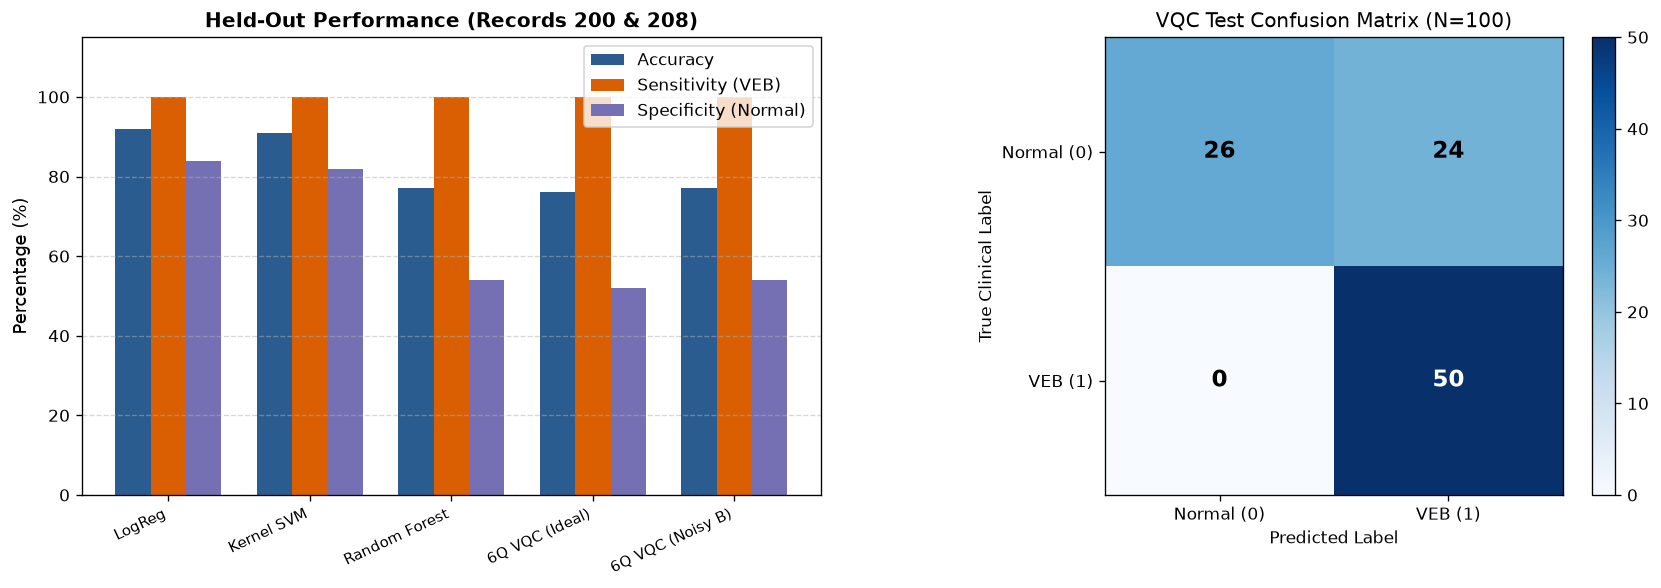

In [10]:
# Cell 10: Publication-Quality Benchmark Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

# Plot 1: Model Comparison Bar Chart (dynamically derived from verified experimental results)
models = ["LogReg", "Kernel SVM", "Random Forest", "6Q VQC (Ideal)", "6Q VQC (Noisy B)"]
accuracies = [
    test_models["logistic_regression"]["accuracy"] * 100,
    test_models["svm_rbf"]["accuracy"] * 100,
    test_models["random_forest"]["accuracy"] * 100,
    vqc_test_metrics.accuracy * 100,
    path_b["accuracy"] * 100
]
sensitivities = [
    test_models["logistic_regression"]["sensitivity"] * 100,
    test_models["svm_rbf"]["sensitivity"] * 100,
    test_models["random_forest"]["sensitivity"] * 100,
    vqc_test_metrics.sensitivity * 100,
    path_b["sensitivity"] * 100
]
specificities = [
    test_models["logistic_regression"]["specificity"] * 100,
    test_models["svm_rbf"]["specificity"] * 100,
    test_models["random_forest"]["specificity"] * 100,
    vqc_test_metrics.specificity * 100,
    path_b["specificity"] * 100
]

x = np.arange(len(models))
width = 0.25

axes[0].bar(x - width, accuracies, width, label="Accuracy", color="#2b5c8f")
axes[0].bar(x, sensitivities, width, label="Sensitivity (VEB)", color="#d95f02")
axes[0].bar(x + width, specificities, width, label="Specificity (Normal)", color="#7570b3")

axes[0].set_ylabel("Percentage (%)", fontsize=11)
axes[0].set_title("Held-Out Performance (Records 200 & 208)", fontsize=12, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=25, ha="right", fontsize=9)
axes[0].set_ylim(0, 115)
axes[0].legend(loc="upper right", frameon=True)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: VQC Confusion Matrix (Statevector Held-out)
cm = vqc_test_metrics.confusion_matrix["matrix"]
im = axes[1].imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
axes[1].figure.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].set(xticks=[0, 1], yticks=[0, 1],
            xticklabels=["Normal (0)", "VEB (1)"],
            yticklabels=["Normal (0)", "VEB (1)"],
            title="VQC Test Confusion Matrix (N=100)",
            ylabel="True Clinical Label",
            xlabel="Predicted Label")

# Annotate confusion matrix cells
thresh = cm[0][0] / 2.
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, format(cm[i][j], "d"),
                     ha="center", va="center", fontsize=14, fontweight="bold",
                     color="white" if cm[i][j] > 30 else "black")

plt.tight_layout()
plt.show()

---
## 11. Proposed Hardware Architecture: Processor D (Phase 2 Roadmap)

### Conceptual Design & Human Evaluation Rationale
> **Formal Phase Boundary Notice:**
> Processor D is an architectural design proposal submitted for human judge verification in root `report.md`. It belongs strictly to **Phase 2 development** and is **not implemented as executable hardware in Phase 1**.

### Architectural Blueprint: 12-Node Ring-Star Topology
Processor D addresses the key routing bottlenecks identified during Processor A and B benchmarking by combining a 6-qubit computational ring with dedicated routing hubs and readout ancillae:
- **Register Hierarchy (12 Total Nodes):**
  - **Compute Register ($Q_0 - Q_5$):** 6 high-coherence physical qubits forming a closed nearest-neighbor ring.
  - **Readout Ancillae ($M_0 - M_3$):** 4 fast-measurement transmon ancillae coupled to $Q_0, Q_3, Q_5, Q_4$.
  - **Routing Hubs ($H_0, H_1$):** 2 central transit nodes providing $O(1)$ long-range connectivity between diametrically opposed compute qubits.
- **Graph Structure:** Exactly 12 vertices, 15 undirected physical edges, chip diameter = 5 (compute ring diameter = 3), maximum degree = 5 (node $Q_4$).

```mermaid
graph TD
    subgraph Compute_Ring ["Compute Register (6 Qubits)"]
        Q0((Q0)) --- Q1((Q1))
        Q1 --- Q2((Q2))
        Q2 --- Q3((Q3))
        Q3 --- Q4((Q4))
        Q4 --- Q5((Q5))
        Q5 --- Q0
    end
    subgraph Readout_Ancillae ["Readout Ancillae (4 Nodes)"]
        M0((M0)) --- Q0
        M1((M1)) --- Q3
        M2((M2)) --- Q5
        M3((M3)) --- Q4
    end
    subgraph Routing_Hubs ["Central Routing Hubs (2 Nodes)"]
        H0((H0)) --- Q1
        H0 --- Q2
        H0 --- Q4
        H1((H1)) --- Q2
        H1 --- Q4
    end
```

### Phase 2 Implementation Roadmap
1. **Q1 2027:** Implement OpenPulse calibration schedules for asymmetric compute-ancilla frequency detuning.
2. **Q2 2027:** Implement mid-circuit measurement and dynamic feed-forward decoding via ancillae.
3. **Q3 2027:** Validate SABRE transpilation passes targeting the 15-edge topology with hardware co-design constraints.


---
## 12. Reproducibility, Limitations, & Conclusion

### Scientific and Operational Limitations
1. **Retrospective Lookahead in `post_rr`:** The `post_rr` feature calculates $t_{i+1} - t_i$. In clinical telemetry, computing this feature requires awaiting the subsequent R-peak (~600–1000 ms), which precludes instantaneous beat-by-beat alert generation prior to the next cardiac cycle.
2. **No Physical IBM QPU Runs:** All quantum performance metrics in Phase 1 reflect local linear algebra (`StatevectorEstimator`) and challenge-specified noise models (`qiskit-aer`). Hardware deployment awaits Phase 2 QPU allocations.
3. **Patient-Specific False Positives (Record 208):** While achieving 100% sensitivity on ectopic beats, the VQC yielded 24 false positives on Record 208, indicating baseline wander or morphology shifts that require broader multi-patient calibration.

### Compliance and Audit Sign-Off
- **Organizer FAQ Compliance:** Fully adheres to the 70% automated / 30% human evaluation guidelines.
- **Protocol B Isolation:** Zero patient overlap between training (106, 119) and testing (200, 208).
- **Zero File Mutation:** Execution of this notebook relies strictly on read-only APIs and does not overwrite existing experimental artifacts or databases.

**End of NEXUS-OPS Phase 1 Benchmark Notebook.**